In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import selfies as sf
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from rdkit import Chem
from rdkit.Chem import Draw, AllChem, DataStructs, rdmolops, Descriptors, rdMolDescriptors, QED
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
import math
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
from sklearn.metrics import r2_score
from IPython.display import display
import seaborn as sns
import os
import re
torch.cuda.empty_cache()

import sys
sys.path.append('/home/andrze06/venvs/mlenv/lib/python3.10/site-packages/rdkit/Contrib/SA_Score')
import sascorer

In [3]:
df = pd.read_csv('/data/home2/andrze06/projects/Smiles-latent-project/data/smiles_selfies_dataset.csv')
print(f"{len(df)} molecules | columns: {list(df.columns)}")
print(df.head())


794403 molecules | columns: ['smiles', 'selfies']
                                              smiles  \
0  O=S(O)c1cc2c(cc1F)OC(c1ccc(F)cc1F)(c1ccc(F)cc1...   
1  CN(C)Cc1cccc(C2Nc3cccc4c(=O)[nH]nc(c34)C2c2ccc...   
2  O=C(N[C@@H](CO)c1nc2cc(Cl)ccc2[nH]1)c1ccc(C(=O...   
3          O=C(Cn1cc(I)cn1)N1CCCc2c1cnn2-c1ccc(F)cc1   
4            Cc1ccc(-c2ccnc(Cl)c2)n1CC(=O)OCc1ccccc1   

                                             selfies  
0  [O][=S][Branch1][C][O][C][=C][C][=C][Branch1][...  
1  [C][N][Branch1][C][C][C][C][=C][C][=C][C][Bran...  
2  [O][=C][Branch2][Ring1][#Branch1][N][C@@H1][Br...  
3  [O][=C][Branch1][N][C][N][C][=C][Branch1][C][I...  
4  [C][C][=C][C][=C][Branch1][N][C][=C][C][=N][C]...  


## Concept-aware SELFIES tokenization (rings, functional groups, halogens)

Plain `sf.split_selfies` gives one token per atom/bond/branch/ring instruction, so a benzene
ring costs 8 tokens (`[C][=C][C][=C][C][=C][Ring1][=Branch1]`) and the model has to learn to
reconstruct that whole pattern from scratch every time it appears. Below we add a layer on top
that recognizes **50 chemical concepts** -- ring scaffolds (benzene, the diazines, the five-membered
N-heterocycles, indole, naphthalene, quinoline, benzofuran, cyclopropane ... morpholine),
**functional groups** (carboxyl, amide, nitro, sulfonamide, sulfone, sulfoxide, urea, carbamate,
ketone, trifluoromethyl, ...) and **halogen substituents** (F, Cl, Br, I) -- and folds each
occurrence into a single vocabulary token, so the model gets them as one semantic unit.

How it works:
1. For every candidate concept we build its *reference token pattern* by encoding a small example
   molecule containing it (e.g. plain `c1ccccc1` for benzene) with the same `sf.encoder`/
   `sf.split_selfies` pipeline used for the real data. For functional groups that need an
   attachment point (acid, amide, ester, ...) the attachment atom is a dummy carbon tagged with
   an isotope label so we can identify and strip it afterwards, leaving just the group's own
   tokens as the pattern.
2. `merge_tokens` scans a molecule's real (atom-level) token list left-to-right and greedily
   replaces any exact, contiguous match of a known pattern (longest patterns first) with a single
   `[FG:name]` super-token.
3. Because a merge only ever collapses an exact, literal run of tokens that were already there,
   it is always losslessly reversible: `expand_token` maps `[FG:name]` back to the exact same
   token string it replaced. So this can never corrupt a molecule -- a concept that isn't written
   in the same local form as our reference example (different canonical ordering, ortho/meta
   di-substitution, a rotated Kekulé placement, ...) simply falls back to plain atom tokens for
   that instance.
4. We only keep patterns that actually occur often enough in the dataset (`MIN_GROUP_COUNT`)
   before finalizing the vocabulary, so we don't waste vocab slots on concepts that never fire.

Notes on the candidate list:
- `carboxyl` (`-C(=O)O`) intentionally covers both carboxylic acids *and* esters: after stripping
  the attachment caps both reduce to the same 5-token pattern, so one super-token handles both.
- `nitrile` (`-C#N`) and `aldehyde` (`-C=O`) collapse to only 2 tokens that start with `[C]` --
  one of the 17 SELFIES index-alphabet symbols -- so they are dropped as too risky to merge.
- The halogen patterns are single tokens (`[F]`, `[Cl]`, `[Br]`, `[I]`); these symbols are *not*
  part of the index alphabet and halogens are always terminal substituents, so length-1 merging
  is unambiguous.

`id2tok` for a merged token is set to its *expansion string* (the concatenated original SELFIES
tokens), so every downstream cell (`tokens_to_selfie`, decoding, attention plots, `sf.decoder`)
keeps working completely unchanged -- `"".join(id2tok[t] for t in tokens)` still reconstructs a
valid SELFIES string whether or not any merging happened.


In [4]:
# --- concept pattern library (ring scaffolds + functional groups + halogens) ----
# Each entry is defined by a small reference molecule containing the concept.
# Ring/scaffold patterns are derived from the plain, unsubstituted ring itself.
# Acyclic functional-group patterns use isotope-tagged dummy carbons as generic
# "attachment points" so the cap atoms can be stripped out afterwards, leaving
# only the group's own tokens.

CAP_A, CAP_B = 98, 99  # isotope labels used purely as removable attachment caps

SCAFFOLD_EXAMPLES = {
    "benzene_ring":         "c1ccccc1",
    "pyridine_ring":        "c1ccncc1",
    "pyrimidine_ring":      "c1cncnc1",
    "pyrazine_ring":        "c1cnccn1",
    "pyridazine_ring":      "c1cnncc1",
    "triazole_ring":        "c1cn[nH]n1",
    "triazine_ring":        "c1ncncn1",
    "isoxazole_ring":       "c1ccno1",
    "oxazole_ring":         "c1ocnc1",
    "thiazole_ring":        "c1cscn1",
    "thiophene_ring":       "c1ccsc1",
    "furan_ring":           "c1ccoc1",
    "pyrrole_ring":         "c1cc[nH]c1",
    "imidazole_ring":       "c1cnc[nH]1",
    "indole_ring":          "c1ccc2[nH]ccc2c1",
    "benzimidazole_ring":   "c1ccc2[nH]cnc2c1",
    "naphthalene_ring":     "c1ccc2ccccc2c1",
    "quinoline_ring":       "c1ccc2ncccc2c1",
    "isoquinoline_ring":    "c1ccc2cnccc2c1",
    "benzofuran_ring":      "c1ccc2occc2c1",
    "benzothiophene_ring":  "c1ccc2sccc2c1",
    "benzothiazole_ring":   "c1ccc2scnc2c1",
    "benzodioxole_ring":    "c1ccc2c(c1)OCO2",
    "cyclopropane_ring":    "C1CC1",
    "cyclobutane_ring":     "C1CCC1",
    "cyclopentane_ring":    "C1CCCC1",
    "cyclohexane_ring":     "C1CCCCC1",
    "pyrrolidine_ring":     "C1CCNC1",
    "piperidine_ring":      "C1CCNCC1",
    "tetrahydrofuran_ring": "C1OCCC1",
    "oxetane_ring":         "C1OCC1",
    "dioxane_ring":         "C1COOCC1",
    "piperazine_ring":      "C1CNCCN1",
    "morpholine_ring":      "C1COCCN1",
}

FUNCTIONAL_GROUP_EXAMPLES = {
    # carboxyl covers both -COOH and -COOR: with the caps stripped they are the same pattern,
    # so 'ester' below is kept only to document (and be deduplicated by) that fact.
    "carboxyl":           f"[{CAP_A}CH3]C(=O)O",
    "ester":              f"[{CAP_A}CH3]C(=O)O[{CAP_B}CH3]",
    "amide":              f"[{CAP_A}CH3]C(=O)N",
    "nitro":              f"[{CAP_A}CH3]N(=O)=O",
    "sulfonamide":        f"[{CAP_A}CH3]S(=O)(=O)N",
    "sulfonic_acid":      f"[{CAP_A}CH3]S(=O)(=O)O",
    "sulfone":            f"[{CAP_A}CH3]S(=O)(=O)[{CAP_B}CH3]",
    "sulfoxide":          f"[{CAP_A}CH3]S([{CAP_B}CH3])=O",
    "nitrile":            f"[{CAP_A}CH3]C#N",
    "trifluoromethyl":    f"[{CAP_A}CH3]C(F)(F)F",
    "urea":               f"[{CAP_A}CH3]NC(=O)N[{CAP_B}CH3]",
    "carbamate":          f"[{CAP_A}CH3]NC(=O)O[{CAP_B}CH3]",
    "ketone":             f"[{CAP_A}CH3]C(=O)[{CAP_B}CH3]",
    "aldehyde":           f"[{CAP_A}CH3]C=O",
    "boronic_acid":       f"[{CAP_A}CH3]B(O)O",
}

# Single-token halogen substituents. [F]/[Cl]/[Br]/[I] are NOT part of the 17-symbol SELFIES
# index alphabet and halogens are always terminal, so length-1 patterns are unambiguous and
# are whitelisted below the usual min_len=3 cutoff.
HALOGEN_EXAMPLES = {
    "fluoro":  f"[{CAP_A}CH3]F",
    "chloro":  f"[{CAP_A}CH3]Cl",
    "bromo":   f"[{CAP_A}CH3]Br",
    "iodo":    f"[{CAP_A}CH3]I",
}


def derive_pattern(example_smiles, strip_caps=False):
    """Encode a reference example molecule and return its SELFIES token pattern."""
    mol = Chem.MolFromSmiles(example_smiles)
    if mol is None:
        raise ValueError(f"could not parse reference SMILES: {example_smiles}")
    canonical = Chem.MolToSmiles(mol)
    tokens = tuple(sf.split_selfies(sf.encoder(canonical)))
    if strip_caps:
        tokens = tuple(t for t in tokens if str(CAP_A) not in t and str(CAP_B) not in t)
    return tokens


def build_candidate_patterns(min_len=3, halogen_min_len=1):
    """Build the {name: pattern} candidate library, deduplicated and length-filtered."""
    raw = {}
    for name, example in SCAFFOLD_EXAMPLES.items():
        raw[name] = derive_pattern(example, strip_caps=False)
    for name, example in FUNCTIONAL_GROUP_EXAMPLES.items():
        raw[name] = derive_pattern(example, strip_caps=True)
    for name, example in HALOGEN_EXAMPLES.items():
        raw[name] = derive_pattern(example, strip_caps=True)

    patterns, seen_patterns, dropped = {}, set(), []
    for name, pattern in raw.items():
        limit = halogen_min_len if name in HALOGEN_EXAMPLES else min_len
        if len(pattern) < limit or pattern in seen_patterns:
            dropped.append(name)
            continue
        patterns[name] = pattern
        seen_patterns.add(pattern)

    if dropped:
        print("Dropped candidates (too short / duplicate of an earlier pattern):")
        for name in dropped:
            print(f"  {name:20s} {' '.join(raw[name])}")

    # longest patterns first -> greedy matching prefers the most specific concept
    return sorted(patterns.items(), key=lambda kv: -len(kv[1]))


candidate_patterns = build_candidate_patterns()
print(f"{len(candidate_patterns)} candidate concept patterns")
for name, pattern in candidate_patterns:
    print(f"  {name:20s} ({len(pattern):2d} tokens): {' '.join(pattern)}")


Dropped candidates (too short / duplicate of an earlier pattern):
  ester                [C] [=Branch1] [C] [=O] [O]
  nitrile              [C] [#N]
  aldehyde             [C] [=O]
50 candidate concept patterns
  benzodioxole_ring    (15 tokens): [C] [=C] [C] [=C] [C] [=Branch1] [Ring2] [=C] [Ring1] [=Branch1] [O] [C] [O] [Ring1] [=Branch1]
  naphthalene_ring     (14 tokens): [C] [=C] [C] [=C] [C] [=C] [C] [=C] [C] [Ring1] [=Branch1] [=C] [Ring1] [#Branch2]
  quinoline_ring       (14 tokens): [C] [=C] [C] [=C] [N] [=C] [C] [=C] [C] [Ring1] [=Branch1] [=C] [Ring1] [#Branch2]
  isoquinoline_ring    (14 tokens): [C] [=C] [C] [=C] [C] [=N] [C] [=C] [C] [Ring1] [=Branch1] [=C] [Ring1] [#Branch2]
  indole_ring          (13 tokens): [C] [=C] [C] [=C] [NH1] [C] [=C] [C] [Ring1] [Branch1] [=C] [Ring1] [=Branch2]
  benzimidazole_ring   (13 tokens): [C] [=C] [C] [=C] [NH1] [C] [=N] [C] [Ring1] [Branch1] [=C] [Ring1] [=Branch2]
  benzofuran_ring      (13 tokens): [C] [=C] [C] [=C] [O] [C] [=C] [C]

In [5]:
# --- merge (tokenize) / expand (detokenize) ------------------------------------

def merge_tokens(tokens, ordered_patterns):
    """Greedily replace exact, contiguous pattern matches with a single '[FG:name]' token.
    Longest patterns are tried first. Falls back to the original token whenever nothing matches,
    so this is always a lossless re-chunking of the same underlying token stream."""
    merged = []
    i, n = 0, len(tokens)
    while i < n:
        matched = False
        for name, pattern in ordered_patterns:
            L = len(pattern)
            if tokens[i:i + L] == list(pattern):
                merged.append(f"[FG:{name}]")
                i += L
                matched = True
                break
        if not matched:
            merged.append(tokens[i])
            i += 1
    return merged


def expand_token(token, pattern_lookup):
    """Inverse of merge_tokens for a single token: '[FG:name]' -> its original token string."""
    if token.startswith("[FG:") and token.endswith("]"):
        return "".join(pattern_lookup[token[4:-1]])
    return token


# sanity check: merging then expanding must always reconstruct the exact original SELFIES string
_pattern_lookup = dict(candidate_patterns)
_sample = df['selfies'].sample(min(500, len(df)), random_state=0)
for _s in _sample:
    _toks = list(sf.split_selfies(_s))
    _merged = merge_tokens(_toks, candidate_patterns)
    _expanded = "".join(expand_token(t, _pattern_lookup) for t in _merged)
    assert _expanded == _s, f"merge/expand round-trip mismatch:\n{_s}\n{_expanded}"
print("round-trip check passed: merge_tokens + expand_token is lossless on the sample")


round-trip check passed: merge_tokens + expand_token is lossless on the sample


In [6]:
# --- Data & Loaders (concept tokenization) --------------------------------------

MIN_GROUP_COUNT = 20  # a candidate pattern only earns its own vocab token if it fires this often

df['base_tokens'] = df['selfies'].apply(lambda x: list(sf.split_selfies(x)))

# first pass: merge with every candidate pattern, count how often each one actually fires
_group_counts = defaultdict(int)
_first_pass = df['base_tokens'].apply(lambda toks: merge_tokens(toks, candidate_patterns))
for _seq in tqdm(_first_pass):
    for _t in _seq:
        if _t.startswith("[FG:"):
            _group_counts[_t[4:-1]] += 1

active_patterns = [(name, pat) for name, pat in candidate_patterns if _group_counts[name] >= MIN_GROUP_COUNT]
active_pattern_lookup = dict(active_patterns)

print("Kept groups (>= %d occurrences):" % MIN_GROUP_COUNT)
for name, pat in active_patterns:
    print(f"  {name:20s} {_group_counts[name]:6d} occurrences  ({len(pat)} base tokens)")
dropped = [name for name, _ in candidate_patterns if name not in active_pattern_lookup]
if dropped:
    print("Dropped (too rare):", ", ".join(dropped))

# final pass with only the active patterns
df['tokens'] = df['base_tokens'].apply(lambda toks: merge_tokens(toks, active_patterns))

vocab = sorted(set(tok for seq in df['tokens'] for tok in seq))
PAD, SOS, EOS = "<PAD>", "<SOS>", "<EOS>"
vocab = [PAD, SOS, EOS] + vocab
vocab_size = len(vocab)

tok2id = {tok: idx for idx, tok in enumerate(vocab)}
# id2tok maps merged group tokens to their *expansion string* (concatenated base SELFIES
# tokens) so every downstream cell that does "".join(id2tok[t] for t in tokens) to rebuild a
# SELFIES string keeps working unchanged, whether or not a given token was merged.
id2tok = {idx: expand_token(tok, active_pattern_lookup) for tok, idx in tok2id.items()}
# id2name keeps the short, human-readable label around for anything that wants it (e.g. nicer
# axis labels in the attention plot) without touching the decoding path above.
id2name = {idx: tok for idx, tok in enumerate(vocab)}

avg_base_len = df['base_tokens'].apply(len).mean()
avg_merged_len = df['tokens'].apply(len).mean()
print(f"\nvocab_size = {vocab_size} ({len(active_patterns)} concept tokens "
      f"+ {vocab_size - len(active_patterns) - 3} atom-level tokens + 3 special tokens)")
print(f"avg sequence length: {avg_base_len:.1f} atom-level tokens -> {avg_merged_len:.1f} merged tokens "
      f"({100 * (1 - avg_merged_len / avg_base_len):.1f}% shorter)")


def molecule_tok2id(tokens, tok2id):
    return np.array([1] + [tok2id[t] for t in tokens] + [2])


df['token_ids'] = df['tokens'].apply(lambda x: molecule_tok2id(x, tok2id))
df['lengths'] = df['tokens'].apply(lambda x: len(x))

# padding
sequences = df['token_ids'].tolist()
max_len = max(len(seq) for seq in sequences)

X_train, X_temp = train_test_split(sequences, test_size=0.2, random_state=42, shuffle=True)
X_val, X_test = train_test_split(X_temp, test_size=0.5, random_state=42, shuffle=True)

class MoleculeDataset(Dataset):
    def __init__(self, X):
        self.X = X

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        tokens = self.X[index]
        return torch.tensor(tokens, dtype=torch.long)

train_data = MoleculeDataset(X_train)
val_data = MoleculeDataset(X_val)
test_data = MoleculeDataset(X_test)
data = MoleculeDataset(sequences)


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 794403/794403 [00:03<00:00, 201533.49it/s]


Kept groups (>= 20 occurrences):
  benzodioxole_ring      2070 occurrences  (15 base tokens)
  naphthalene_ring       2812 occurrences  (14 base tokens)
  quinoline_ring          732 occurrences  (14 base tokens)
  isoquinoline_ring       153 occurrences  (14 base tokens)
  indole_ring             661 occurrences  (13 base tokens)
  benzimidazole_ring      340 occurrences  (13 base tokens)
  benzofuran_ring         150 occurrences  (13 base tokens)
  benzothiophene_ring     167 occurrences  (13 base tokens)
  benzothiazole_ring       78 occurrences  (13 base tokens)
  benzene_ring         240674 occurrences  (8 base tokens)
  pyridine_ring         10146 occurrences  (8 base tokens)
  pyrimidine_ring        1527 occurrences  (8 base tokens)
  pyrazine_ring          1124 occurrences  (8 base tokens)
  pyridazine_ring         240 occurrences  (8 base tokens)
  cyclohexane_ring      12034 occurrences  (8 base tokens)
  piperidine_ring        3743 occurrences  (8 base tokens)
  piperazine_r

In [7]:
# utilities
def collate_fn(batch):
    max_len = max(t.shape[0] for t in batch)
    B = len(batch)

    padded_sequence = torch.zeros((B, max_len), dtype=torch.long)

    for i, tokens in enumerate(batch):
        padded_sequence[i, :len(tokens)] = tokens

    return padded_sequence

@torch.no_grad()
def accuracy(model, loader, mode='eval', pad_id=0, device='cuda'):
    model.eval()

    total_correct = 0
    total_tok = 0
    total_seq = 0
    perfect = 0

    for x in loader:
        x = x.to(device)

        if mode == 'train':
            logits, _, _, _ = model(x, None, mode=mode)
            targets = x[:, 1:]

            pred = logits.argmax(dim=-1)

            mask = (targets != pad_id)

            correct = (pred == targets) & mask

            total_correct += correct.sum().item()
            total_tok += mask.sum().item()

            seq_correct = (correct.sum(dim=1) == mask.sum(dim=1))
            perfect += seq_correct.sum().item()
            total_seq += x.size(0)

        else:
            tokens, _, _, _ = model(x, None, mode='eval')

            for i, pred in enumerate(tokens):
                true = x[i]
                mask = (true != pad_id)
                true_len = mask.sum().item()

                if true_len == 0:
                    continue
                if len(pred) < true_len:
                    pad = torch.full((true_len - len(pred),), pad_id, device=pred.device, dtype=pred.dtype)
                    pred = torch.cat([pred, pad], dim=0)
                else:
                    pred = pred[:true_len]

                true = true[:true_len]
                correct = (pred == true)
                total_correct += correct.sum().item()
                total_tok += true_len
                perfect += int(correct.all())
                total_seq += 1

    return (
        total_correct / max(total_tok, 1),
        perfect / max(total_seq, 1)
    )

def set_token_ticks(ax, tokens, max_show=30):
    n = len(tokens)

    step = max(1, n // max_show)
    idxs = list(range(0, n, step))

    labels = [tokens[i] for i in idxs]

    ax.set_xticks(idxs)
    ax.set_yticks(idxs)

    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

def cleaned_selfie(tokens, pad="<PAD>", sos="<SOS>", eos="<EOS>"):
    out = []
    for t in tokens:
        if t == eos:
            break
        if t in (pad, sos):
            continue
        out.append(t)
    return out


In [8]:
# model
class PositionalEmbedding(nn.Module):
    def __init__(self, max_len, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        pe = torch.zeros(max_len, hidden_size)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, hidden_size, 2).float() * (-math.log(10000.0) / hidden_size))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x):
        if x.dim() == 3:
            B, T, _ = x.shape
        elif x.dim() == 2:
            B, T = x.shape
        if T <= self.pe.size(0):
            pe = self.pe[:T]  
        else:
            device = x.device
            H = self.hidden_size
            position = torch.arange(T, dtype=torch.float, device=device).unsqueeze(1)  
            div_term = torch.exp(torch.arange(0, H, 2, device=device).float() * (-math.log(10000.0)/H))
            pe = torch.zeros(T, H, device=device)
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)  

class MultiHeadAttention(nn.Module):
    def __init__(self, hidden_size, num_heads):
        super().__init__()
        self.d = hidden_size // num_heads
        self.num_heads = num_heads
        self.W_q = nn.Linear(hidden_size, hidden_size, bias=False)
        self.W_k = nn.Linear(hidden_size, hidden_size, bias=False)
        self.W_v = nn.Linear(hidden_size, hidden_size, bias=False)
        self.W_o = nn.Linear(hidden_size, hidden_size, bias=False)
        self.norm1 = nn.LayerNorm(hidden_size)
        self.ff = nn.Sequential(
            nn.Linear(hidden_size, 2*hidden_size),
            nn.GELU(),
            nn.Dropout(p=0.1),
            nn.Linear(2*hidden_size, hidden_size),
            nn.Dropout(p=0.1)
        )
        self.norm2 = nn.LayerNorm(hidden_size)

    def forward(self, q, k, v, pad_mask=None):   # [B, T, H]
        # q,k,v: attention values [B, T, H]
        B, T_q, H = q.shape
        _, T_v, _ = v.shape
        Q = self.W_q(q)     # [B, T, num_heads * H]
        K = self.W_k(k)
        V = self.W_v(v)
        Q = Q.view(B, self.num_heads, T_q, self.d) # [B, A, T, H]
        K = K.view(B, self.num_heads, T_v, self.d)
        V = V.view(B, self.num_heads, T_v, self.d)

        attn_logits = torch.einsum('baih,bajh->baij', Q, K)    # [B, A, T, H] @ [B, A, H, T] = [B, A, T, T]

        if pad_mask is not None:
            key_mask = pad_mask[:, None, None, :]  # [B,1,1,T_k]
            attn_logits = attn_logits.masked_fill(~key_mask, float('-inf'))

        attn = F.softmax(attn_logits / math.sqrt(self.d), dim=-1)

        if pad_mask is not None:
            query_mask = pad_mask[:, None, :, None]  # [B,1,T_q,1]
            attn = attn * query_mask.float()

        h = torch.einsum('baij,bajh->baih',attn, V)  # [B, A, T, H]
        h = h.view(B, T_q, H)  # [B, T, A*H]
        h = self.W_o(h)     # [B, T, H]
        
        h = q + self.W_o(h)     # [B, T, H]
        h = h + self.ff(self.norm2(h))
        h = self.norm1(h)
        return h, attn

class MultiSlotPooling(nn.Module):
    def __init__(self, hidden_size, num_slots):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(num_slots, hidden_size))
        self.W_k = nn.Linear(hidden_size, hidden_size, bias=False)
        self.W_v = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, h, mask):
        # h: [B, T, D]
        # mask: [B, T]
        k = self.W_k(h)
        v = self.W_v(h)
        attn = torch.einsum("kd,btd->bkt", self.queries, k)
        attn = attn.masked_fill(~mask[:, None, :], -1e9)
        attn = F.softmax(attn, dim=-1)
        slots = torch.einsum("bkt,btd->bkd", attn, v)
        return slots


class VaeTransformer(nn.Module):
    def __init__(self, vocab_size, hidden_size, latent_size, max_len, attn_heads=8, num_slots=8, encoder_layers=1, decoder_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_slots = num_slots
        self.embedding = nn.Embedding(vocab_size, hidden_size)
        self.pos_encoder = PositionalEmbedding(max_len, hidden_size)
        self.conv_pos = nn.Conv1d(hidden_size, hidden_size, kernel_size=3, padding=1, groups=hidden_size)
        
        # Encoder
        self.pos_block = MultiHeadAttention(hidden_size, attn_heads)
        self.encoder_blocks = nn.ModuleList([MultiHeadAttention(hidden_size, attn_heads) for _ in range(encoder_layers)])
        self.pool = MultiSlotPooling(hidden_size, num_slots=num_slots)
        #self.slot_pos_encoder = nn.Parameter(torch.randn(1, num_slots, hidden_size))
        self.slots_mix = MultiHeadAttention(hidden_size, num_heads=num_slots)

        self.slot_gamma = nn.Parameter(torch.ones(1, num_slots, hidden_size))
        self.slot_beta = nn.Parameter(torch.zeros(1, num_slots, hidden_size))
        #nn.init.orthogonal_(self.slot_beta[0])

        # VAE heads
        self.slot_mu = nn.Linear(hidden_size, latent_size)
        self.slot_logvar = nn.Linear(hidden_size, latent_size)  
        
        self.slot_compress_mu = nn.Linear(hidden_size, latent_size // num_slots)
        self.slot_compress_logvar = nn.Linear(hidden_size, latent_size // num_slots)

        self.fc_mu = nn.Linear(hidden_size, latent_size)
        self.fc_logvar = nn.Linear(hidden_size, latent_size)
        
        # pooling in latent space with uncertanty
        self.latent_query = nn.Parameter(torch.randn(1, 1, latent_size))
        self.latent_key = nn.Linear(latent_size, latent_size)

        # Decoder
        self.max_len = max_len
        self.z_to_slot = nn.Linear(hidden_size // num_slots, hidden_size)
        #self.slot_pos_decoder = nn.Parameter(torch.randn(1, num_slots, hidden_size))
        self.decoder_embed = nn.Embedding(vocab_size, hidden_size)

        self.decoder_pos = PositionalEmbedding(max_len, hidden_size)

        self.z_to_memory = nn.Linear(latent_size, hidden_size)
        self.slots_to_memory = nn.Linear(latent_size // num_slots, hidden_size)

        self.decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden_size,
            nhead=attn_heads,
            dim_feedforward=2 * hidden_size,
            batch_first=True
        )

        self.decoder_transformer = nn.TransformerDecoder(
            self.decoder_layer,
            num_layers=decoder_layers
        )
        # Output head
        self.fc_output = nn.Linear(hidden_size, vocab_size)
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def causal_mask(self, T, device):
        return torch.triu(
            torch.ones(T, T, device=device),
            diagonal=1
        ).bool()
    
    def encode(self, x, D, mode=None):  
        B, _ = x.shape
        h = self.embedding(x)    # [B, T, H]
        fourier_pos_encoding = self.pos_encoder(x)
        h = h + fourier_pos_encoding

        mask = (x != 0)
        
        for block in self.encoder_blocks:
            h, attn_matrix = block(h, h, h, pad_mask=mask)
            
        h = h.masked_fill(~mask[:, :, None], 0.0)

        # h = h.sum(dim=1) / mask.sum()
        # mu = self.fc_mu(h)
        # logvar = self.fc_logvar(h)
        slots = self.pool(h, mask)
        slots = F.layer_norm(slots, slots.shape[-1:])
        #slots = slots * self.slot_gamma + self.slot_beta

        B, K, Z = slots.shape

        slots_mu = self.slot_mu(slots)
        slots_logvar = self.slot_logvar(slots)

        # Latent pool from slots with uncertanty
        q = F.normalize(self.latent_query.expand(B, 1, Z), dim=-1)
        k = F.normalize(self.latent_key(slots_mu), dim=-1)

        logits = torch.einsum("bqz,bkz->bqk", q, k)

        confidence = -torch.logsumexp(slots_logvar, dim=-1).unsqueeze(1) #-slots_logvar.mean(dim=-1).unsqueeze(1)
        confidence_scale = 0.5

        logits = logits + confidence_scale * confidence
        attn = torch.softmax(logits / 0.5, dim=-1)

        mu = torch.einsum("bqk,bkz->bqz", attn, slots_mu).squeeze(1)

        var = torch.exp(slots_logvar)
        var_agg = torch.einsum("bqk,bkz->bqz", attn, var).squeeze(1)
        logvar = torch.log(var_agg + 1e-8)
        
        if mode == "test":
            return mu, logvar, attn_matrix
        else:
            return mu, logvar

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z, x_in=None, max_len=80, start_id=1, eos_id=2):
        B = z.size(0)
        device = z.device

        memory = self.z_to_memory(z).unsqueeze(1)

        if x_in is not None:
            x_emb = self.decoder_embed(x_in)
            x_emb = x_emb + self.decoder_pos(x_emb)

            T = x_emb.size(1)
            tgt_mask = self.causal_mask(T, device)

            h = self.decoder_transformer(
                tgt=x_emb,
                memory=memory,
                tgt_mask=tgt_mask
            )

            logits = self.fc_output(h)   
            return logits

        else:
            tokens = torch.full((B, 1), start_id, dtype=torch.long, device=device)
            finished = torch.zeros(B, dtype=torch.bool, device=device)
            max_len = self.max_len * 2

            for _ in range(max_len):
                x_emb = self.decoder_embed(tokens)
                x_emb = x_emb + self.decoder_pos(x_emb)

                T = tokens.size(1)
                tgt_mask = self.causal_mask(T, device)

                h = self.decoder_transformer(
                    tgt=x_emb,
                    memory=memory,
                    tgt_mask=tgt_mask
                )

                logits_step = self.fc_output(h[:, -1])  # [B, V]

                next_token = torch.argmax(logits_step, dim=-1, keepdim=True)

                next_token = torch.where(
                    finished.unsqueeze(1),
                    torch.full_like(next_token, eos_id),
                    next_token
                )

                tokens = torch.cat([tokens, next_token], dim=1)

                finished |= (next_token.squeeze(1) == eos_id)

                if finished.all():
                    break

            return tokens
            
    def forward(self, x, D, mode='eval'):
        mu, logvar = self.encode(x, D)
        z = self.reparameterize(mu, logvar)

        if mode == 'train':
            x_in = x[:, :-1]

            logits = self.decode(z, x_in=x_in)

            return logits, mu, logvar, z
    
        if mode == "eval":
            tokens = self.decode(z, x_in=None)

            return tokens, mu, logvar, z
        
        if mode == "test":
            mu, logvar, attn_matrix = self.encode(x, D, mode="test")
            z = self.reparameterize(mu, logvar)

            tokens = self.decode(z, x_in=None)

            return tokens, mu, logvar, attn_matrix, z


def vae_loss(logits, targets, mu, logvar, beta=0.01, pad_id=0):
    B, T, V = logits.shape

    logits = logits.reshape(-1, V)
    targets = targets.reshape(-1)

    rec_loss = F.cross_entropy(
        logits,
        targets,
        ignore_index=pad_id
    )

    kl = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())

    return rec_loss + beta * kl, rec_loss, kl

In [9]:
# training
device = 'cuda' if torch.cuda.is_available() else 'cpu'

hidden_size = 256
attention_heads = 8
num_slots = 8
encoder_layers = 3
decoder_layers = 2
latent_size = 256

model = VaeTransformer(vocab_size, hidden_size, latent_size, max_len, attn_heads=attention_heads, num_slots=num_slots, encoder_layers=encoder_layers, decoder_layers=decoder_layers).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)

beta = 0.01
epochs = 50
batch_size = 256
history = []

train_loader = DataLoader(train_data, batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_data, batch_size, shuffle=False, collate_fn=collate_fn)

for epoch in range(1, epochs+1):
    #beta = min(0.5, beta + epoch/30)
    model.train()
    total = 0
    total_rec = 0
    total_kl = 0
    total_val = 0
    pbar = tqdm(train_loader)

    for x in pbar:
        x = x.to(device)
        logits, mu, logvar, z = model(x, None, mode='train')
        x = x[:, 1:]
        loss, rec, kl = vae_loss(logits, x, mu, logvar, beta=beta)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        pbar.set_postfix({
            "rec": f"{rec.item():.3f}",
            "kl": f"{kl.item():.3f}",
            "tot": f"{loss.item():.3f}",
        })
        total += loss.item()
        total_rec += rec.item()
        total_kl += kl.item()

    with torch.no_grad():
        model.eval()
        for x in val_loader:
            x = x.to(device)
            logits, mu, logvar, z = model(x, None, mode='train')
            x = x[:, 1:]
            val_loss, val_rec, val_kl = vae_loss(
                logits, x, mu, logvar,
                beta=beta
            )
            total_val += val_loss.item()

    token_acc, seq_acc = accuracy(model, val_loader, mode='train')
    total = total / len(train_loader)
    total_rec = total_rec / len(train_loader)
    total_kl = total_kl / len(train_loader)
    total_val = total_val / len(val_loader)
    history.append((total, total_rec, total_kl, total_val))
    print(f"Epoch: {epoch:03d} | total={total:.4f} | rec={total_rec:.4f} | kl={total_kl:.4f} | val={total_val:.4f} | token_acc={token_acc*100:.2f}% | seq_acc={seq_acc*100:.2f}%")


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2483/2483 [02:09<00:00, 19.13it/s, rec=0.562, kl=2.539, tot=0.588]


Epoch: 001 | total=1.1251 | rec=1.1053 | kl=1.9825 | val=0.4491 | token_acc=85.48% | seq_acc=8.36%


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2483/2483 [02:03<00:00, 20.18it/s, rec=0.323, kl=2.537, tot=0.349]


Epoch: 002 | total=0.4492 | rec=0.4237 | kl=2.5503 | val=0.2340 | token_acc=92.75% | seq_acc=29.02%


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2483/2483 [02:03<00:00, 20.18it/s, rec=0.216, kl=2.485, tot=0.241]


...

Epoch: 048 | total=0.0401 | rec=0.0286 | kl=1.1468 | val=0.0187 | token_acc=99.76% | seq_acc=93.76%


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2483/2483 [02:02<00:00, 20.19it/s, rec=0.039, kl=1.164, tot=0.050]


Epoch: 049 | total=0.0396 | rec=0.0282 | kl=1.1420 | val=0.0182 | token_acc=99.77% | seq_acc=94.03%


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2483/2483 [02:02<00:00, 20.20it/s, rec=0.036, kl=1.155, tot=0.048]


Epoch: 050 | total=0.0394 | rec=0.0280 | kl=1.1389 | val=0.0184 | token_acc=99.76% | seq_acc=93.90%


In [10]:
# save the model
torch.save(model.state_dict(), "/data/home2/andrze06/projects/Smiles-latent-project/ProbeVAE/trained_models/H256-L256-3E-2D-ConceptSelfies.pt")


In [11]:
# utils
def get_molecule_properties(mol):
    return {
        "molWt": Descriptors.MolWt(mol),
        "HeavyAtomCount": mol.GetNumHeavyAtoms(),
        "cLogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "NumRotatableBonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol),
        "AromaticRingCount": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumSpiroAtoms": rdMolDescriptors.CalcNumSpiroAtoms(mol),
        "NumBridgeheadAtoms": rdMolDescriptors.CalcNumBridgeheadAtoms(mol),
        "BertzCT": Descriptors.BertzCT(mol),
        "QED": QED.qed(mol),
        "SA-score": sascorer.calculateScore(mol)
    }

def compute_property(mol, name):
    if name == "molWt":
        return Descriptors.MolWt(mol)
    elif name == "HeavyAtomCount":
        return mol.GetNumHeavyAtoms()
    elif name == "cLogP":
        return Descriptors.MolLogP(mol)
    elif name == "TPSA":
        return Descriptors.TPSA(mol)
    elif name == "HBD":
        return rdMolDescriptors.CalcNumHBD(mol)
    elif name == "HBA":
        return rdMolDescriptors.CalcNumHBA(mol)
    elif name == "NumRotatableBonds":
        return rdMolDescriptors.CalcNumRotatableBonds(mol)
    elif name == "RingCount":
        return rdMolDescriptors.CalcNumRings(mol)
    elif name == "AromaticRingCount":
        return rdMolDescriptors.CalcNumAromaticRings(mol)
    elif name == "FractionCSP3":
        return rdMolDescriptors.CalcFractionCSP3(mol)
    elif name == "NumSpiroAtoms":
        return rdMolDescriptors.CalcNumSpiroAtoms(mol)
    elif name == "NumBridgeheadAtoms":
        return rdMolDescriptors.CalcNumBridgeheadAtoms(mol)
    elif name == "BertzCT":
        return Descriptors.BertzCT(mol)
    elif name == "QED":
        return QED.qed(mol)
    elif name == "SA-score":
        return sascorer.calculateScore(mol)
    else:
        return np.nan

def clean_selfie_ids(ids):
    result = []
    for tok in ids:
        if tok == 1:
            continue
        if tok == 2 or tok == 0:
            return result
        result.append(tok)
    return result

def latents_to_mol(model, z):
    ids = model.decode(z)
    tokens = [[id2tok[id] for id in clean_selfie_ids(seq)] for seq in ids.cpu().numpy()]
    selfies = [''.join(toks) for toks in tokens]
    mols = []
    for selfie in selfies:
        try:
            smi = sf.decoder(selfie)
            mol = Chem.MolFromSmiles(smi)
            mols.append(mol)  
        except:
            mols.append(None)
            print(smi)
    return mols

def set_token_ticks(ax, tokens, max_show=30):
    n = len(tokens)

    step = max(1, n // max_show)
    idxs = list(range(0, n, step))

    labels = [tokens[i] for i in idxs]

    ax.set_xticks(idxs)
    ax.set_yticks(idxs)

    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

def cleaned_selfie(tokens, pad="<PAD>", sos="<SOS>", eos="<EOS>"):
    out = []
    for t in tokens:
        if t == eos:
            break
        if t in (pad, sos):
            continue
        out.append(t)
    return out

In [12]:
Y = pd.read_csv('/data/home2/andrze06/projects/Smiles-latent-project/data/molecule_properties.csv')
X = pd.read_csv('/data/home2/andrze06/projects/Smiles-latent-project/data/confound_features.csv')    

In [13]:
n = len(Y) // 100
latent_size = latent_size
batch_size = 2048

Sampled_properties = []
with torch.no_grad():
    for i in tqdm(range(0, n, batch_size)):
        z = torch.randn((min(batch_size, n - i), latent_size)).to(device)
        mols = latents_to_mol(model, z)
        for mol in mols:
            if mol is not None:
                props = get_molecule_properties(mol)
                Sampled_properties.append(props)
            else:
                Sampled_properties.append(None)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:24<00:00,  6.07s/it]


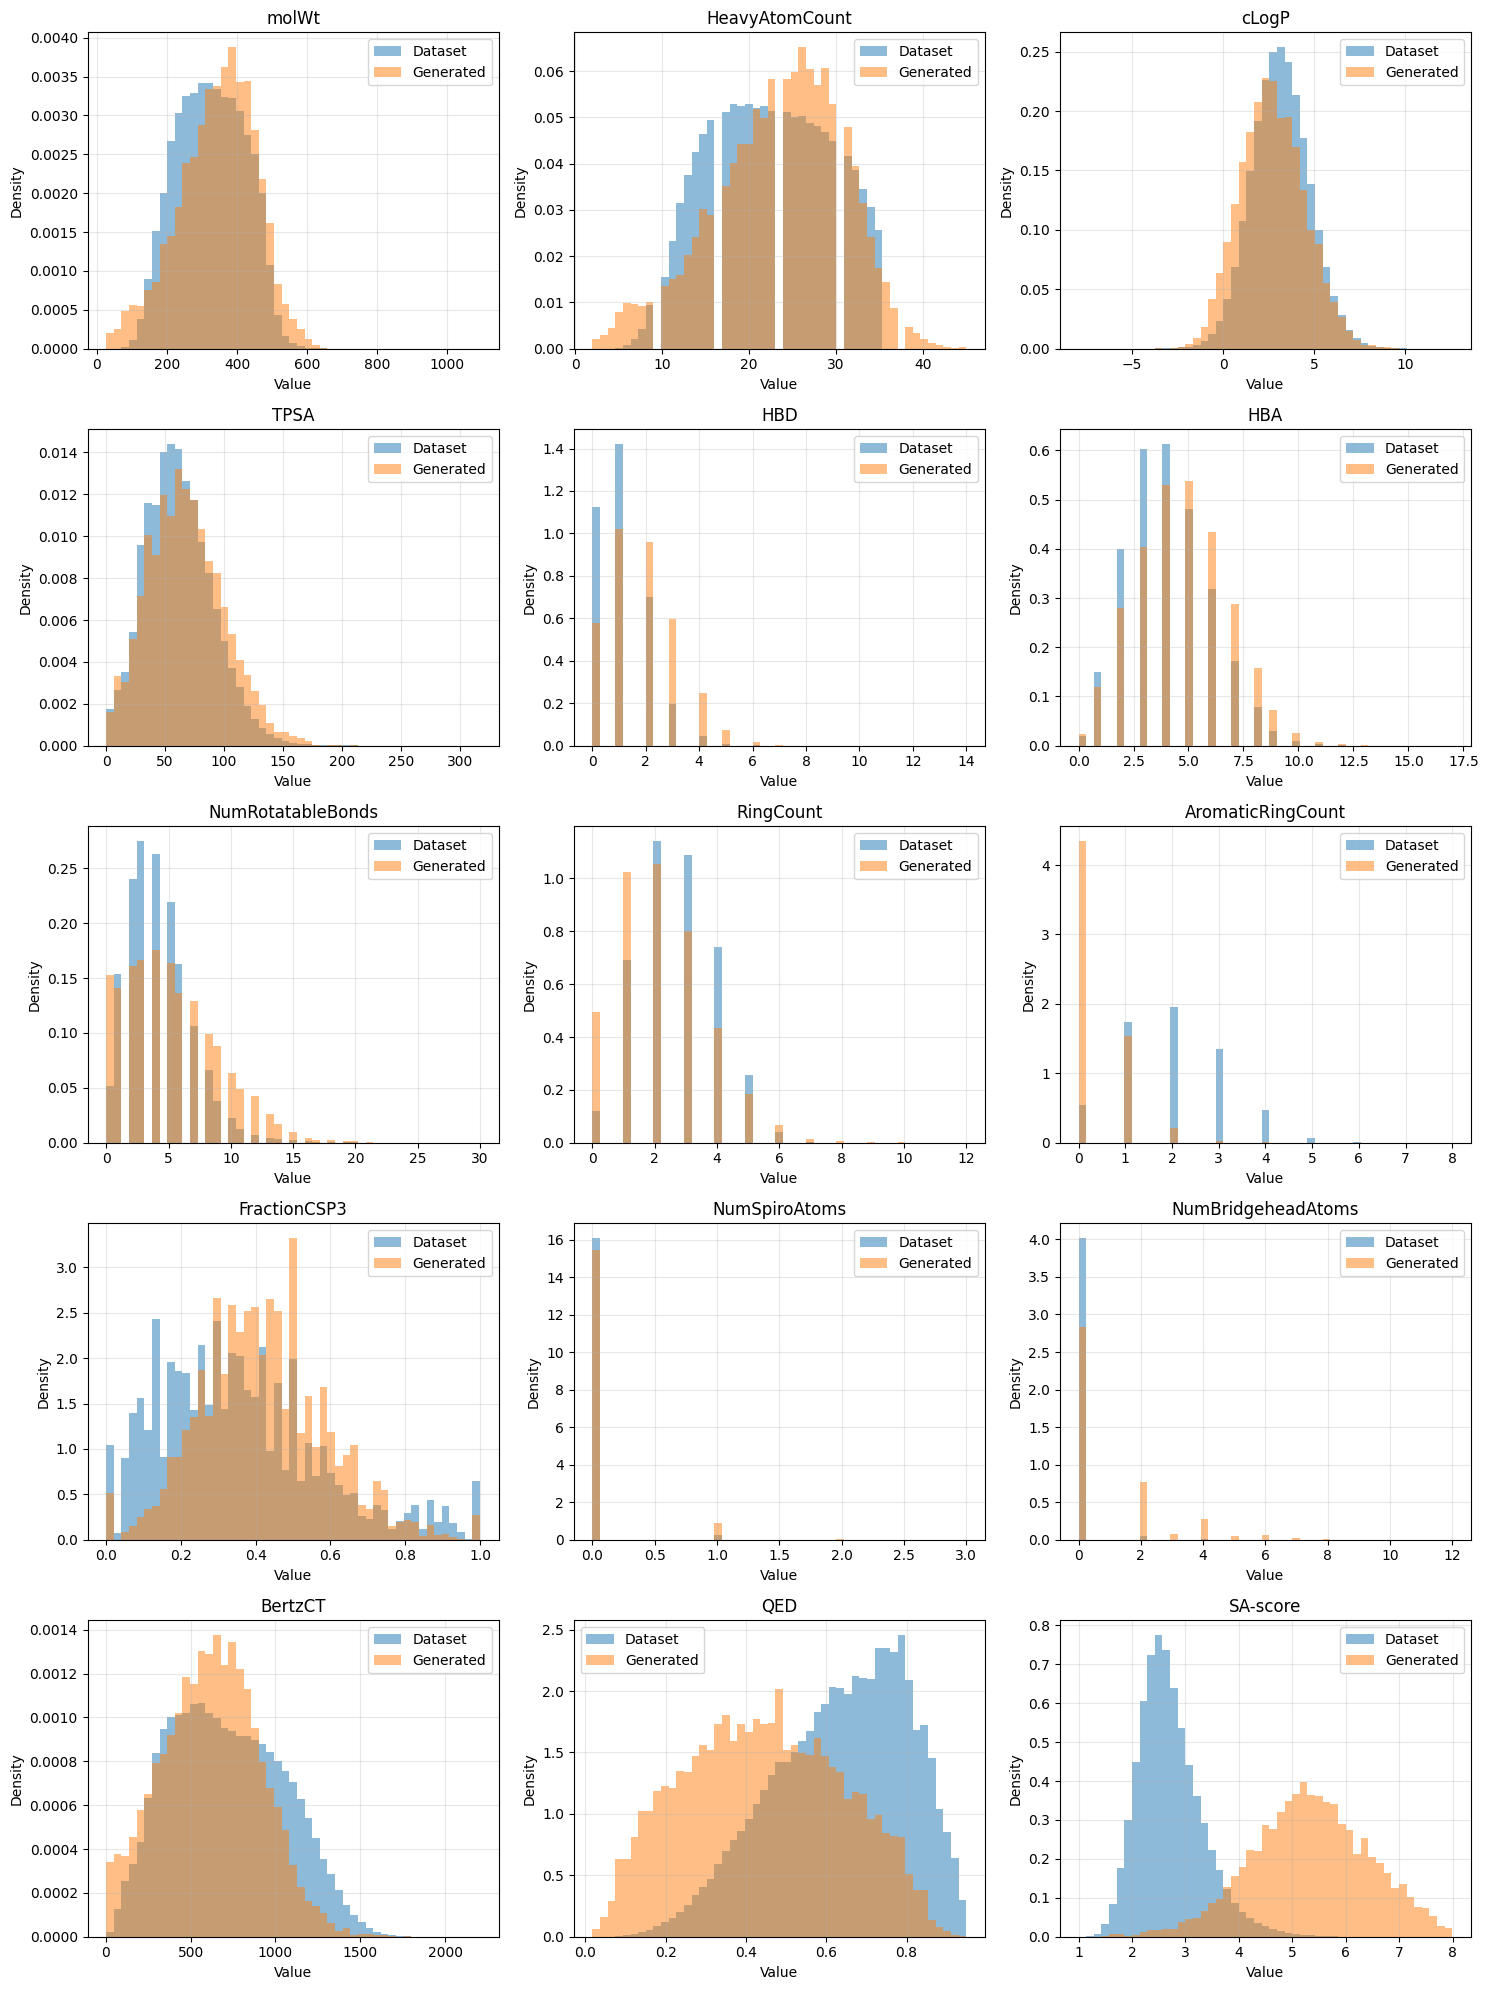

In [15]:
# plots
prop_dict = defaultdict(list)

for props in Sampled_properties:
    if props is None:
        continue
    for k, v in props.items():
        if v is not None and not np.isnan(v):
            prop_dict[k].append(v)

cols = Y.columns
n_cols = len(cols)

n_rows = math.ceil(n_cols / 3)
n_cols_grid = 3

fig, axes = plt.subplots(n_rows, n_cols_grid, figsize=(5 * n_cols_grid, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    gen_vals = prop_dict.get(col, [])

    if len(gen_vals) == 0:
        continue

    data_vals = Y[col].dropna()

    combined = np.concatenate([data_vals.values, gen_vals])
    bins = np.linspace(combined.min(), combined.max(), 50)

    axes[i].hist(data_vals, bins=bins, alpha=0.5, label="Dataset", density=True)
    axes[i].hist(gen_vals, bins=bins, alpha=0.5, label="Generated", density=True)

    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Density")
    axes[i].grid(alpha=0.3)
    axes[i].legend()

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [16]:
# examples:
def tokens_to_selfie(tokens):
    selfie_tokens = [id2tok[int(t)] for t in tokens]
    return "".join(selfie_tokens)

model.eval()
with torch.no_grad():
    for x in val_loader:
        x = x.to(device)
        tokens, _, _, attn_matrix, _ = model(x, None, mode='test')
        for i in range(5):
            toks = tokens[i]
            print(tokens_to_selfie(x[i]))
            print(tokens_to_selfie(toks))
            print("")
        break


<SOS>[C][C][C][C][=C][Branch2][Ring1][Branch2][C][=Branch1][C][=O][N][C][C][=C][C][=C][C][=C][Branch1][C][O][C][=C][C][Ring1][#Branch1][=C][Ring1][O][C][=N][N][Ring2][Ring1][Ring2][C][=C][C][=C][C][=C][Ring1][=Branch1]<EOS><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
<SOS>[C][C][C][C][=C][Branch2][Ring1][Branch2][C][=Branch1][C][=O][N][C][C][=C][C][=C][C][=C][Branch1][C][O][C][=C][C][Ring1][#Branch1][=C][Ring1][O][C][=N][N][Ring2][Ring1][Ring2][C][=C][C][=C][C][=C][Ring1][=Branch1]<EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS>

<SOS>[C][C][C][C][O][S][=Branch1][C][=O][=Branch1][C][=O][N][C][=Branch1][C][=O][/C][=C][/C][C][Branch1][C][C][=N][N][Branch1][C][C][C][=Ring1][#Branch1][N][C][=C][C][=C][C][Branch1][C][Cl][=C][C][=C][Ring1][#Branch1][Ring1][#Branch2]<EOS><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><P

<SOS>[C][S][C][=C][C][=C][C][=Branch1][Ring2][=C][Ring1][=Branch1][C][N][Branch1][=Branch1][C][Branch1][C][C][C][S][=Branch1][C][=O][=Branch1][C][=O][N][Ring1][N][C][C][Cl]<EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS><EOS>


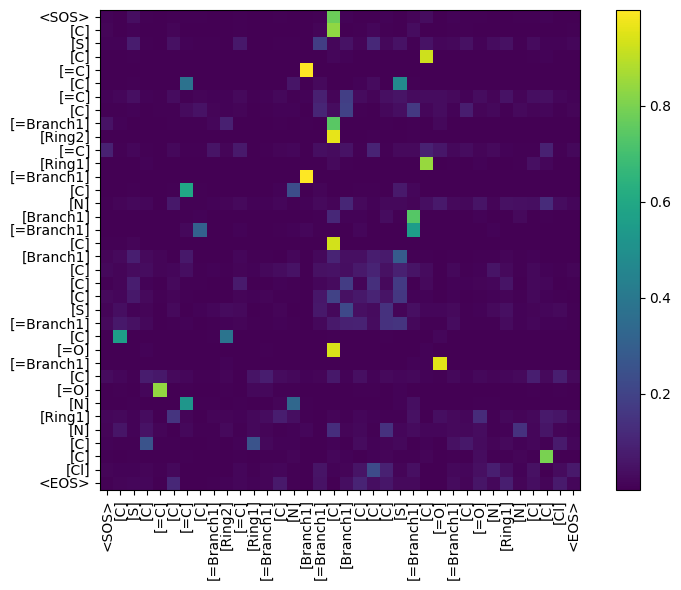

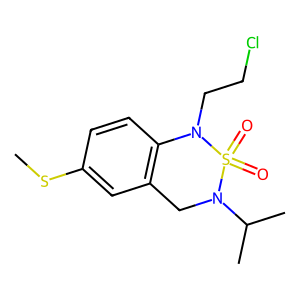

In [17]:
# attention visualization
idx = np.random.randint(0, tokens.size(0))
toks = tokens[idx]

eos_id = 2
tokens_np = toks.detach().cpu().numpy()
eos_pos = np.where(tokens_np == eos_id)[0]

if len(eos_pos) > 0:
    cut = eos_pos[0] + 1   
else:
    cut = len(tokens_np)

valid_tokens = tokens_np[:cut]
selfies_tokens = [id2tok[int(t)] for t in valid_tokens]
selfies = tokens_to_selfie(toks)
print(selfies)

def crop_attn(A, cut):
    return A[:cut, :cut]

A1 = crop_attn(attn_matrix[idx][0].cpu(), cut)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(A1, cmap="viridis")

# tick labels only for visible tokens
ax.set_xticks(range(cut))
ax.set_yticks(range(cut))

ax.set_xticklabels(selfies_tokens, rotation=90)
ax.set_yticklabels(selfies_tokens)

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()
selfies_str = "".join(cleaned_selfie(selfies_tokens))

try:
    smiles = sf.decoder(selfies_str)
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print("RDKit failed to parse SMILES")
    else:
        img = Draw.MolToImage(mol)
        display(img)
except Exception as e:
    print("SELFIES decode failed:", e)

In [18]:
zs = []
lenghts = []
with torch.no_grad():
    for i, x in enumerate(val_loader):
        x = x.to(device)
        mu, _ = model.encode(x, None)
        zs.append(mu.cpu().numpy())

        lenght = (x != 0).sum(dim=-1)
        lenghts.append(lenght.cpu().numpy())

        if i >= 100:
            break

z = np.concatenate(zs, axis=0)
lenghts = np.concatenate(lenghts, axis=0)
print(z.shape, lenghts.shape)


(25856, 256) (25856,)


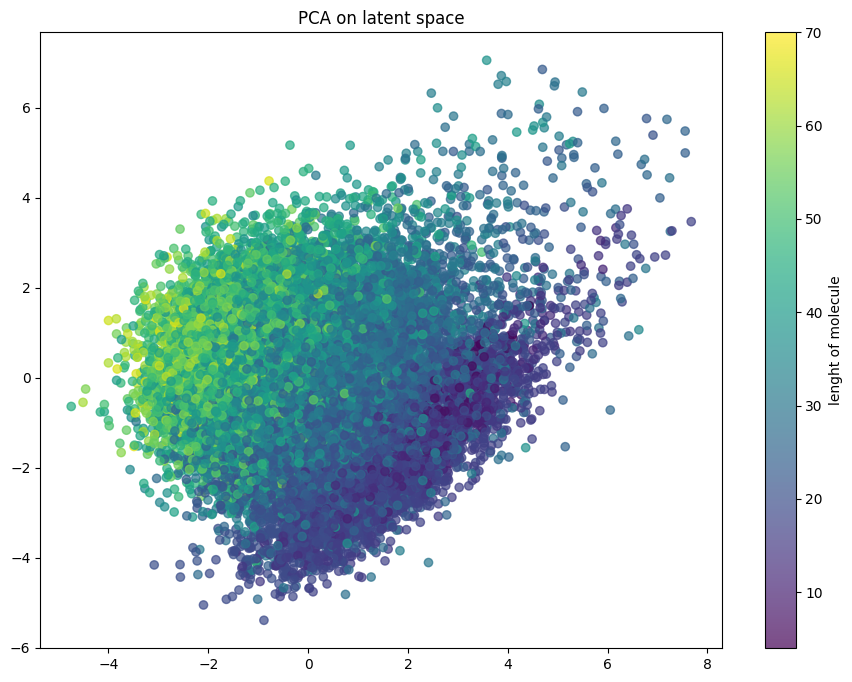

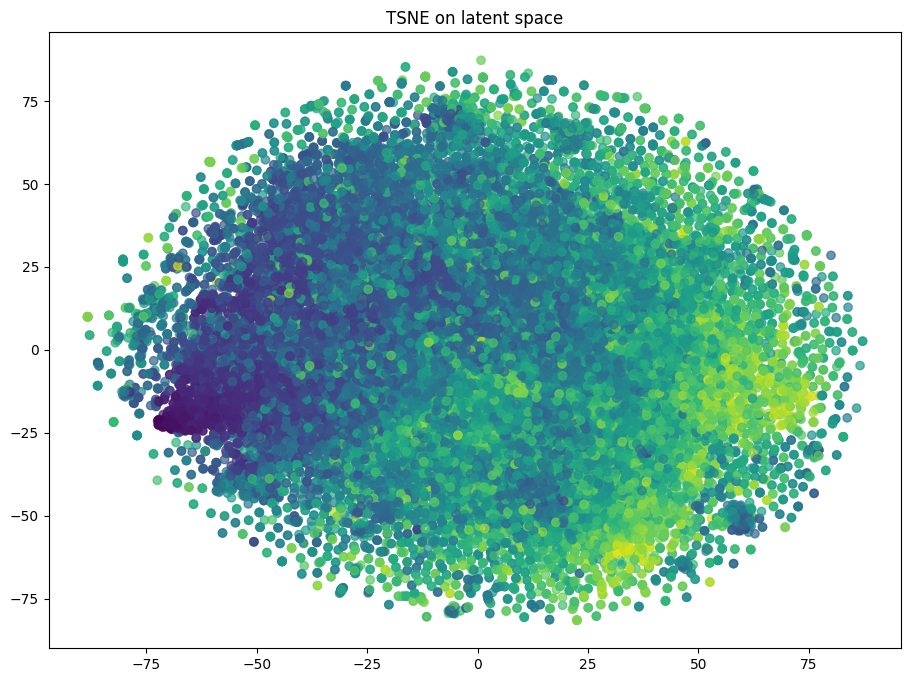

In [19]:
# visualizations
pca_z = PCA(n_components=2).fit_transform(z)
plt.figure(figsize=(11,8))
plt.scatter(pca_z[:, 0], pca_z[:, 1], c=lenghts, cmap='viridis', alpha=0.7)
plt.title('PCA on latent space')
plt.colorbar(label='lenght of molecule')
plt.show()

tsne_z = TSNE(n_components=2).fit_transform(z)
plt.figure(figsize=(11,8))
plt.scatter(tsne_z[:, 0], tsne_z[:, 1], c=lenghts, cmap='viridis', alpha=0.7)
plt.title('TSNE on latent space')
plt.show()

In [20]:
# extract latents for linear probe
def extract_latents(data, model):
    loader = DataLoader(data, batch_size=128, shuffle=False, collate_fn=collate_fn)
    zs = []
    model.eval()
    with torch.no_grad():
        for x in tqdm(loader):
            x = x.to(device)
            mu, _ = model.encode(x, None)
            zs.append(mu.cpu().numpy())
    z = np.concatenate(zs, axis=0)
    return z

z = extract_latents(data, model)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6207/6207 [00:32<00:00, 189.08it/s]


In [21]:
directions = []
for target_name in Y.columns:
    print(f"\n=== Predicting {target_name} ===")
    y = Y[target_name].values
    z_train, z_test, y_train, y_test = train_test_split(z, y, test_size=0.2, random_state=42)

    linear_probe = Pipeline([
        ("scaler", StandardScaler()),
        ("linear", LinearRegression())
    ])

    linear_probe.fit(z_train, y_train)
    y_pred = linear_probe.predict(z_test)
    print("R2:", r2_score(y_test, y_pred))
    w = linear_probe.named_steps['linear'].coef_ / linear_probe.named_steps['scaler'].scale_
    w /= np.linalg.norm(w)
    directions.append(w)


=== Predicting molWt ===
R2: 0.912069363066052

=== Predicting HeavyAtomCount ===
R2: 0.9507188200950623

=== Predicting cLogP ===
R2: 0.7208831100558946

=== Predicting TPSA ===
R2: 0.7118918260910714

=== Predicting HBD ===
R2: 0.31171536445617676

=== Predicting HBA ===
R2: 0.7597939968109131

=== Predicting NumRotatableBonds ===
R2: 0.5693104267120361

=== Predicting RingCount ===
R2: 0.8689299821853638

=== Predicting AromaticRingCount ===
R2: 0.8457399010658264

=== Predicting FractionCSP3 ===
R2: 0.7976125456946739

=== Predicting NumSpiroAtoms ===
R2: 0.07620471715927124

=== Predicting NumBridgeheadAtoms ===
R2: 0.10890311002731323

=== Predicting BertzCT ===
R2: 0.9227457988005392

=== Predicting QED ===
R2: 0.30882940267020964

=== Predicting SA-score ===
R2: 0.5259202830981572


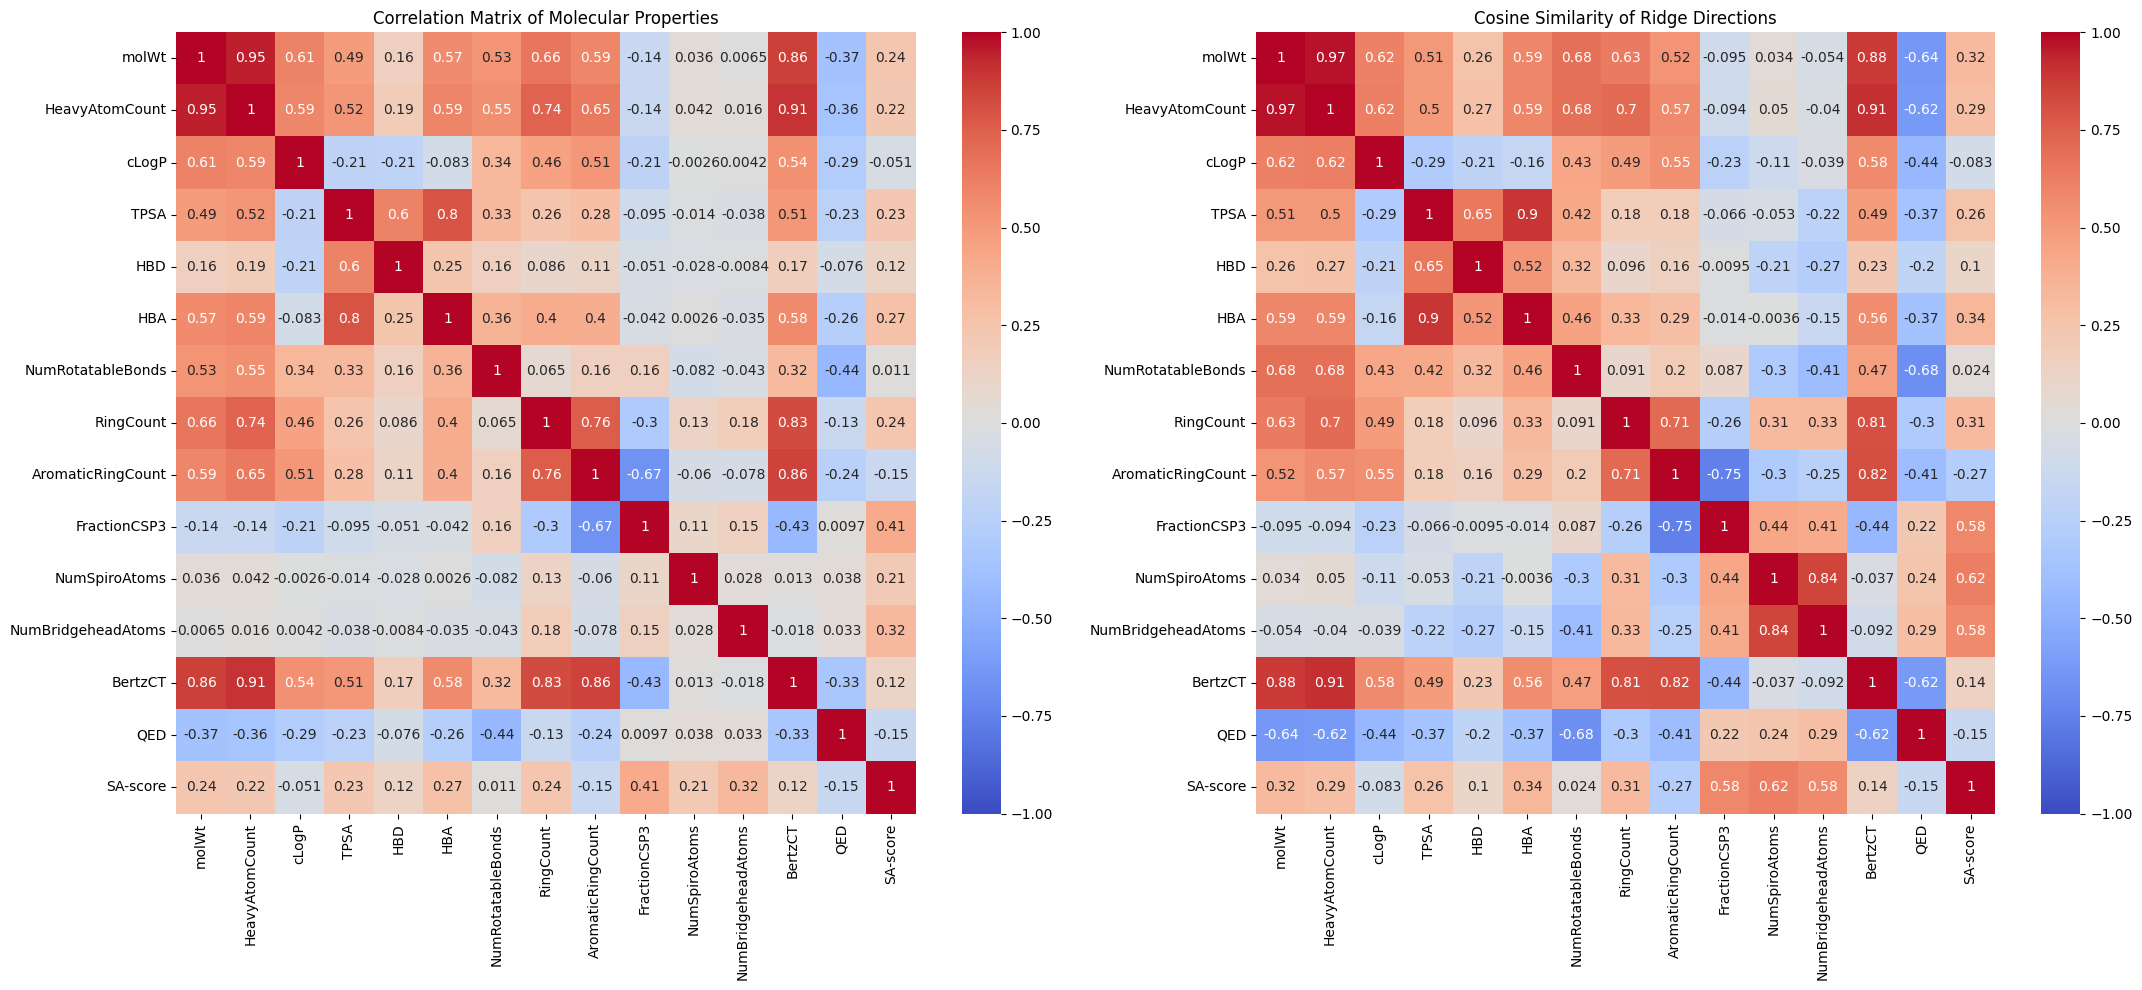

In [22]:
# plot correlation
corr_properties = Y.corr()
w = np.array(directions)
ridge_similarities = np.dot(w, w.T)
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

sns.heatmap(corr_properties,annot=True, cmap="coolwarm",vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation Matrix of Molecular Properties")
sns.heatmap(ridge_similarities,annot=True,cmap="coolwarm",vmin=-1, vmax=1, xticklabels=Y.columns, yticklabels=Y.columns, ax=axes[1])
axes[1].set_title("Cosine Similarity of Ridge Directions")

plt.tight_layout()
plt.show()